# Example: A Synthetic Market of Many Stocks
In this example, we extend the jump hidden Markov model from one asset to a universe of stocks. Each synthetic stock's growth rate is the sum of a baseline, a market component, a sector component, and a stock-specific residual. The shared market and sector components make stocks move together.

We check that the synthetic stocks move together the way the real ones do. We also compare the stylized facts of one synthetic stock with its real growth rates. Then we save the fitted model, which we call the generator, so we can draw new synthetic markets later.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Separate the growth-rate components:__ Fit the single index model to each stock, and build each sector's factor from the residuals of the stocks in that sector.
> * __Build the synthetic universe and compare its co-movement:__ Combine the saved market model with fitted models of the sector factors and the stock-specific residuals. Compare correlations within and across sectors, and each stock's volatility and market sensitivity, between a synthetic path and the real data.
> * __Check the stylized facts of one synthetic stock:__ Simulate many paths of the universe, with and without jumps. Compare the distribution, the autocorrelation, and the volatility clustering of the growth rate of a stock we choose with its real growth rates, at the two endpoints and for a mix of the two.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
We load daily prices (2014 to 2024) with [the `MyTrainingMarketDataSet()` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyTrainingMarketDataSet) and each firm's sector in the [Global Industry Classification Standard (GICS)](https://www.msci.com/our-solutions/indexes/gics) with [the `MySP500SectorDataSet()` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MySP500SectorDataSet).

The universe is `SPY` plus every stock in the data with the full 2014 to 2024 price history and a GICS sector. We use every such stock, so that each sector factor averages many stocks. A firm with two classes of shares, such as News Corp, keeps one ticker.

The `tickers::Array{String,1}` array lists `SPY` first, then the stocks in sector order. The `prices::Array{Float64,2}` array holds closing prices (days × tickers). The `sectors::Array{String,1}` array holds sector labels for the stocks, excluding `SPY`:


In [2]:
tickers, prices, sectors = let

    # Load the data: daily prices (2014 to 2024) and GICS sectors -
    dataset = MyTrainingMarketDataSet()["dataset"]; # 2014 to 2024, one DataFrame per ticker
    sector_table = MySP500SectorDataSet(); # GICS sector of each firm
    sector_of = Dict{String,String}(); # ticker => GICS sector
    firm_of = Dict{String,Int}(); # ticker => CIK number, which identifies the firm
    for row ∈ eachrow(sector_table)
        sector_of[row.Symbol] = row."GICS Sector";
        firm_of[row.Symbol] = row.CIK;
    end

    # the rule: every stock with the full 2014 to 2024 history and a GICS sector, one ticker per firm -
    number_of_rows = nrow(dataset["SPY"]); # trading days in the full history
    candidates = String[]; # tickers that pass the rule
    firms_seen = Int[]; # CIK numbers of the firms already in the list
    for t ∈ sort(collect(keys(dataset))) # alphabetical order
        if t != "SPY" && nrow(dataset[t]) == number_of_rows && haskey(sector_of, t)
            if !(firm_of[t] ∈ firms_seen) # a firm with two share classes keeps its first ticker
                push!(candidates, t); # full history, a known sector, and a new firm
                push!(firms_seen, firm_of[t]);
            end
        end
    end

    # the sectors, each listed once, in alphabetical order -
    sector_names = String[];
    for t ∈ candidates
        if !(sector_of[t] ∈ sector_names)
            push!(sector_names, sector_of[t]); # a sector we have not seen yet
        end
    end
    sort!(sector_names);

    # sort the stocks by sector, so each sector forms one block -
    universe = String[];
    for s ∈ sector_names
        for t ∈ candidates
            if sector_of[t] == s
                push!(universe, t); # the stocks of sector s, in alphabetical order
            end
        end
    end

    # the tickers: SPY (the market) first, then the stocks -
    tickers = ["SPY"];
    append!(tickers, universe); # add the stocks to the end of the list, after SPY

    # closing prices: one row per trading day, one column per ticker (USD/share) -
    prices = zeros(number_of_rows, length(tickers));
    for j ∈ 1:length(tickers)
        prices[:, j] = dataset[tickers[j]].close; # column j holds the closing prices of tickers[j]
    end

    # the sector of each stock, SPY excluded -
    sectors = String[]; # start with an empty list of sector labels
    for t ∈ universe
        push!(sectors, sector_of[t]); # add the sector of stock t to the end of the list
    end
    println("$(length(universe)) stocks in $(length(sector_names)) sectors");

    # checks: full history for every ticker, and at least two stocks in every sector -
    for t ∈ tickers
        @assert nrow(dataset[t]) == number_of_rows "every ticker needs the full 2014-2024 history"
    end
    for s ∈ sector_names
        @assert count(sectors .== s) >= 2 "every sector needs at least two stocks" # sectors .== s is true for each stock in sector s
    end

    # return -
    (tickers, prices, sectors)
end;

375 stocks in 11 sectors


### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values:

In [3]:
Δt = 1/252; # one trading day, expressed in years
number_of_states = 100; # number of hidden states in every jump hidden Markov model
ν = 5.0; # degrees of freedom of the Student-t distribution in each state
random_seed = 5660; # fix the random numbers, so every run gives the same paths
ϵ_range = range(1e-4, 5e-3, length = 6); # length = 6: six equally spaced candidate episode-start probabilities per day
λ_range = range(10.0, 160.0, length = 6); # length = 6: six equally spaced candidate mean episode lengths (trading days)
number_of_paths = 50; # simulated paths used to score each candidate (ϵ, λ) pair during tuning

my_ticker = "AMD"; # the stock we compare in Task 3; any ticker in tickers except SPY
number_of_paths_per_group = 100; # synthetic paths of my_ticker in each group of Task 3: no jumps, and with jumps
maximum_number_of_draws = 2000; # upper limit on the universe paths drawn for the group with jumps, so the simulation always stops
fraction_with_jumps = 0.5; # the mix of Task 3: the share of its number_of_paths_per_group paths with jumps; 0 = none, 0.65 = 65%, 1 = all
number_of_lags = 252; # lags (trading days) of the autocorrelation checks in Task 3, about one trading year
lower_percentile = 5; # lower edge of the shaded range in the last figure of Task 3, in percent of the synthetic paths
upper_percentile = 95; # upper edge of the shaded range in the last figure of Task 3; 0 ≤ lower_percentile < upper_percentile ≤ 100

# compute the daily growth rates of every ticker, in units of 1/yr (annualized)
G = JumpHMM.excess_growth_rates(prices;
    rf = 0.0, # annual risk-free growth rate to subtract (1/yr); zero keeps total growth
    Δt = Δt # time between closing prices, in years; used to annualize the growth rate
); # daily growth rates, days × tickers (1/yr)

# Get some dimensions of the data, for later use. 
number_of_days = size(G, 1); # number of growth rates (trading days)
number_of_stocks = length(tickers) - 1; # stocks in the universe, SPY excluded

___

## Task 1: Fit the Sector Factor Model
In this task, we reuse the tuned `SPY` model from the single-asset example to fit the sector factor model. 

[The `JumpHMM.build(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/api/#JumpHMM.build-Tuple{Type{MyPortfolioModel},%20NamedTuple}) fits the model in three steps:
* __Market:__ It regresses each stock's growth rate $g_{i}(t)$ on the `SPY` growth rate $g_{m}(t)$ (the single index fit). This gives the baseline $\alpha_{i}$, the market sensitivity $\beta_{i}$, and the single index residual $\varepsilon_{i}(t)=g_{i}(t)-\alpha_{i}-\beta_{i}\,g_{m}(t)$, the part of the growth rate that the fit does not explain.
* __Sector:__ The sector factor $f_{s}(t)$ is the average single index residual of the $n_{s}$ stocks in sector $s$. The sector loading $\delta_{i}$ measures how strongly $\varepsilon_{i}(t)$ moves with the sector factor computed without stock $i$. Removing the sector part $\delta_{i}\,f_{s}(t)$ from $\varepsilon_{i}(t)$ leaves the stock-specific residual $u_{i}(t)$.
* __Jump hidden Markov models:__ The sector factor $f_{s}(t)$ and the stock-specific residual $u_{i}(t)$ are daily growth rates, like the growth rates of `SPY`. It fits a single-asset jump hidden Markov model to each of these growth rate series, as the single-asset example does for `SPY`.

We store the market model in `market_model::JumpHMM.MyJumpHiddenMarkovModel` and the fitted generator in `portfolio::JumpHMM.MyPortfolioModel`:

In [4]:
market_model, portfolio = let

    # load the tuned market model saved by the single-asset example -
    market_path = joinpath(_PATH_TO_DATA, "JumpHMM-SPY-2014-2024.jld2");
    market_model = load(market_path, "model");

    # fit the sector and stock residual models, retaining the saved market model -
    time_to_fit = @elapsed portfolio = JumpHMM.build(JumpHMM.MyPortfolioModel, (
        tickers = tickers, # one ticker per column of prices, SPY first
        prices = prices, # closing prices (USD/share), one row per trading day
        dependence = JumpHMM.MySectorFactorModel, # link stocks through shared market and sector components
        market = "SPY", # ticker whose price column supplies the market growth rates
        sector = sectors, # one sector label per non-market ticker, in the same order
        number_of_states = number_of_states, # growth-rate states in each newly fitted component model
        ν = ν, # Student-t degrees of freedom within each state; smaller values give heavier tails
        rf = 0.0, # annual risk-free growth rate to subtract (1/yr); zero keeps total growth
        Δt = Δt, # time between closing prices, in years
        sector_options = ( # additional fitting options passed to the sector factor model
            market_model = market_model, # reuse the tuned SPY model loaded above
        )
    ));
    # digits sets the number of decimal places in the displayed summaries (here: 1).
    println("fit in $(round(time_to_fit, digits = 1)) s");

    # checks: compatible growth rates, the saved market model, and all component models -
    # The saved model's Laplace location equals the median of the SPY growth rates it was fit to.
    # A model fit with a different rf or Δt has a different location and fails this check.
    @assert market_model.Δt == Δt && market_model.laplace_μ == median(G[:, 1]) "the saved market model must use the same growth-rate convention"
    @assert portfolio.dependence.market_model === market_model "reuse the saved SPY model"
    @assert length(portfolio.dependence.own_models) == number_of_stocks "one residual model per stock"
    @assert length(portfolio.dependence.sector_models) == length(unique(sectors)) "one model per sector"

    # return -
    (market_model, portfolio)
end;


fit in 1.9 s


__Let's look at what the fit found in each sector__. Each row of the table is one sector, with its number of stocks $n_{s}$ and the averages over these stocks of the single index estimate $\hat{\beta}_{i}$ and of $R^{2}$. The $R^{2}$ of a stock is the fraction of the variance of its growth rate that the market explains.

The last column is the sector average of the sector loading $\delta_{i}$:

In [5]:
let

    # initialize: the fitted sector factor model, and the sectors in the order of the stocks -
    dep = portfolio.dependence;
    sector_names = unique(dep.sector);

    # one row per sector: the number of stocks and the sector averages -
    df = DataFrame(sector = String[], n = Int[], β = Float64[], R² = Float64[], δ = Float64[]);
    for s ∈ sector_names
        members = findall(dep.sector .== s); # positions of the stocks in sector s
        push!(df, (s, length(members), mean(dep.β[members]), mean(dep.r²[members]), mean(dep.δ[members])));
    end

    # let's display the sector averages in a table -
    pretty_table(df;
        column_labels = ["sector", "n_s", "average β̂", "average R²", "average δ"], # displayed column headings
        alignment = [:l, :r, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [3, 4, 5])], # print the selected numeric columns to three decimal places
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
end

 ------------------------ ----- ----------- ------------ -----------
  sector                   n_s   average β̂   average R²   average δ 
 ------------------------ ----- ----------- ------------ -----------
  Communication Services    14       0.896        0.291       0.687
  Consumer Discretionary    39       1.094        0.313       0.917
  Consumer Staples          31       0.604        0.202       0.934
  Energy                    16       1.199        0.267       0.975
  Financials                54       1.088        0.447       0.977
  Health Care               44       0.858        0.293       0.924
  Industrials               60       1.011        0.394       0.946
  Information Technology    50       1.240        0.429       0.931
  Materials                 17       1.041        0.331       0.875
  Real Estate               24       0.865        0.301       0.968
  Utilities                 26       0.637        0.213       0.981
 ------------------------ ----- ----------- 

> __What do we see?__ In every sector, the average $R^{2}$ is well below one: the market explains only part of the daily moves of a typical stock in that sector.
>
> The average sector loading is positive in every sector. A positive $\delta_{i}$ means that the single index residual $\varepsilon_{i}(t)$ of stock $i$, on average, moves with the residuals of the other stocks in its sector. After we remove the market, the stocks in each sector still move together.

___

## Task 2: Simulate the Synthetic Universe
In this task, we tune the jump behavior of the sector and stock residual models. Then we simulate one path of the whole universe. The saved `SPY` model stays fixed.

* [The `JumpHMM.tune(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/tuning/) searches a grid of $(\epsilon,\lambda)$ values, as in the single-asset example, for the pair whose simulated paths best match the kurtosis and the volatility clustering of each model's data. Here $\epsilon$ is the daily probability that an episode starts, and $\lambda$ is the mean episode length in days.

* [The `JumpHMM.sample_dependence(...)` function](https://varnerlab.github.io/JumpHMM.jl/dev/sector_factor/) then draws one path. Every stock shares the market draw, and every stock in a sector shares the sector draw. We save the tuned model in `tuned::JumpHMM.MyPortfolioModel`, the stock growth rates in `G_syn::Array{Float64,2}` (days × stocks), and the market growth rates in `g_m_syn::Array{Float64,1}`:

Let's run this block:

In [6]:
tuned, G_syn, g_m_syn = let

    # If we have already tuned the sector and stock residual models, we can load the saved generator instead of tuning again. 
    # Tuning takes several minutes, so we check that the saved generator matches the universe and the tuning settings. If it does, we reuse it; otherwise, we tune again.
    # the generator saved at the end of Task 3: reuse it if it was tuned with the same settings, because tuning takes minutes -
    path = joinpath(_PATH_TO_DATA, "JumpHMM-SectorFactor-Universe-2014-2024.jld2");
    use_saved = false; # true when the saved generator matches the universe and the tuning settings
    if isfile(path) == true # great, we have the file!
        saved = load(path);
        if haskey(saved, "number_of_paths") == true # files saved before this check do not record the tuning settings
            same_universe = (saved["tickers"] == tickers && saved["N"] == number_of_states && saved["ν"] == ν && saved["Δt"] == Δt);
            same_tuning = (saved["ϵ_range"] == collect(ϵ_range) && saved["λ_range"] == collect(λ_range) &&
                saved["number_of_paths"] == number_of_paths && saved["seed"] == random_seed);
            use_saved = (same_universe && same_tuning);
        end
    end

    # load the saved generator, or tune the sector and stock residual models; the stock-only map leaves the saved SPY model fixed -
    if use_saved == true
        tuned = saved["portfolio"]; # the tuned generator from an earlier run
        println("loaded the tuned model from data/$(basename(path)); delete this file to tune again");
    else
        
        # Ok, if we get here, we do not have a saved generator that matches the universe and the tuning settings. 
        # We tune the sector and stock residual models, retaining the saved market model. 
        #The tuning searches a grid of (ϵ, λ) values for the pair whose simulated paths best match the kurtosis and the volatility clustering of each model's data.
        stock_columns = Dict{String,Int}(); # ticker => column of prices, stocks only
        for t ∈ portfolio.tickers
            stock_columns[t] = portfolio.tickers_map[t]; # column of stock t in prices
        end
        time_to_tune = @elapsed tuned = JumpHMM.tune(portfolio, prices;
            tickers_map = stock_columns, # stock columns in prices; omitting SPY keeps its saved market model fixed
            ϵ_range = ϵ_range, # candidate daily probabilities of starting a jump episode
            λ_range = λ_range, # candidate mean episode lengths, in trading days
            number_of_paths = number_of_paths, # simulated paths used to score each candidate (ϵ, λ) pair
            seed = random_seed # reproduce the random draws used during tuning
        );
        # digits sets the number of decimal places in the displayed summaries (here: 1).
        println("tuned in $(round(time_to_tune, digits = 1)) s");
    end

    # simulate one path of the whole universe -
    d = JumpHMM.sample_dependence(tuned.dependence, number_of_days;
        seed = random_seed # reproduce all market, sector, stock residual, and β draws
    );

    # checks: the saved market model, one column per stock, and finite growth rates -
    @assert tuned.dependence.market_model.transition == market_model.transition "tuning must preserve the saved SPY model"
    @assert size(d.G) == (number_of_days, number_of_stocks) "unexpected size of the synthetic path"
    @assert all(isfinite, d.G) "synthetic growth rates must be finite"

    # return -
    (tuned, d.G, d.g_m)
end;

loaded the tuned model from data/JumpHMM-SectorFactor-Universe-2014-2024.jld2; delete this file to tune again


__Let's compare how the stocks move together__. We compute the correlation matrix of the daily growth rates for the real data, the single index model, and the synthetic paths.

We store the correlation matrices of the real data, the single index model, and the synthetic path in the `C_real::Array{Float64,2}`, `C_sim::Array{Float64,2}`, and `C_syn::Array{Float64,2}` variables (stocks × stocks):

In [7]:
C_real, C_sim, C_syn = let

    # initialize: correlation matrices of the real and synthetic growth rates of the stocks -
    G_real = G[:, 2:end]; # drop SPY
    C_real = cor(G_real); # real correlation matrix
    C_syn = cor(G_syn); # synthetic correlation matrix

    # the correlation matrix of the single index model, from the real data -
    β = tuned.dependence.β; # single index market sensitivity of each stock
    var_m = var(G[:, 1]); # variance of the real market growth rate (1/yr^2)
    C_sim = zeros(number_of_stocks, number_of_stocks); # single index correlation matrix
    for i ∈ 1:number_of_stocks
        for j ∈ 1:number_of_stocks
            if i == j
                C_sim[i, j] = 1.0; # a stock is perfectly correlated with itself
            else
                C_sim[i, j] = β[i] * β[j] * var_m / (std(G_real[:, i]) * std(G_real[:, j])); # market part only
            end
        end
    end

    # return -
    (C_real, C_sim, C_syn)
end;

`Unhide` the code block below to see how we plotted the two correlation matrices. With the stocks in sector order, each sector is a block on the diagonal.

The left panel shows the real data. The `C_model` variable at the top of the code block sets the right panel: `C_syn` plots the synthetic path of the sector factor model, and `C_sim` plots the single index model.

> __What do we see?__ The real matrix and the synthetic path both show the sector blocks on the diagonal. The single index matrix has no blocks, only light and dark stripes. A stock that moves closely with the market has a light row and column.
>
> The single index model sets the residual covariance of two stocks to zero. The sector factor adds this covariance back for stocks in the same sector.
>
> The real matrix also shows pairs of sectors that move together more than the market explains, such as Real Estate and Utilities. The sector models are drawn independently. Only the shared market draw links different sectors.

Do the synthetic stocks move together like the real ones?

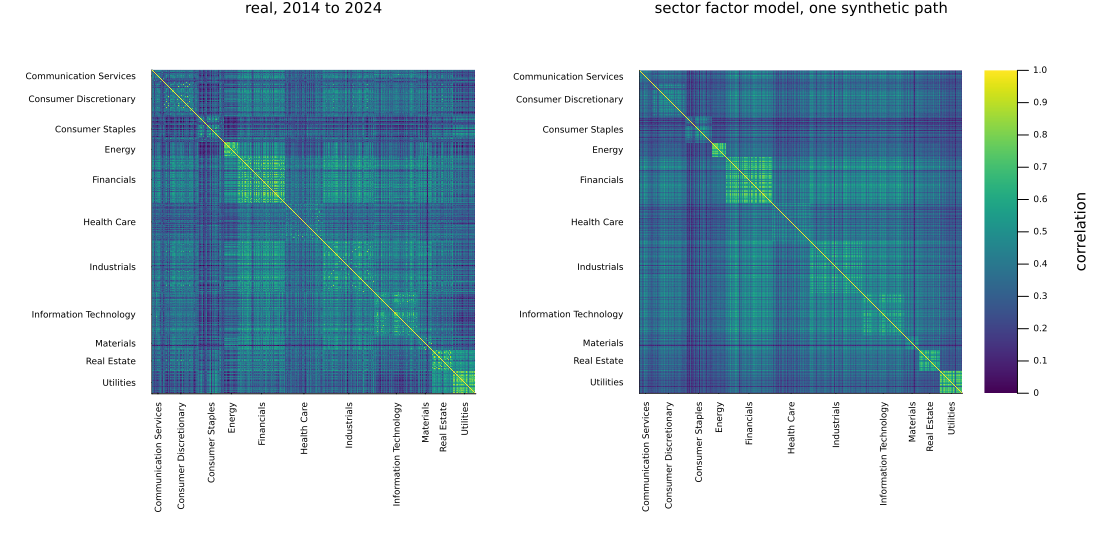

In [8]:
let

    # the right panel: C_syn plots the synthetic path of the sector factor model, C_sim plots the single index model -
    C_model = C_syn; # change to C_sim and re-run this cell to plot the single index model

    # initialize: the sectors, in the order of the stocks -
    dep = tuned.dependence;
    sector_names = unique(dep.sector); # the sectors, in the order of the stocks

    # the title of the right panel, from the matrix it shows -
    title_model = ""; # stays empty if C_model is neither model
    if C_model == C_syn
        title_model = "sector factor model, one synthetic path";
    elseif C_model == C_sim
        title_model = "single index model";
    end

    # one tick at the middle of each sector block, labeled with the sector -
    tick_positions = Float64[];
    for s ∈ sector_names
        members = findall(dep.sector .== s); # positions of the stocks in sector s
        push!(tick_positions, (first(members) + last(members)) / 2); # middle of the block
    end

    # plot: the real data and the model, on one color scale, with the axes fit to the matrix -
    n = number_of_stocks; # rows and columns of each correlation matrix
    ticks = (tick_positions, sector_names); # label each sector block
    # display options used in this cell -
    # clims: Fix the heatmap color scale to the specified lower and upper values.
    # c: Choose the series color or, for a heatmap, the color palette.
    # yflip: Put the first matrix row at the top of the heatmap.
    # title: Set the title above each panel.
    # xticks: Set the x-axis tick positions and their labels.
    # yticks: Set the y-axis tick positions and their labels.
    # titlefontsize: Set the panel title font size in points.
    # xrotation: Rotate the x-axis tick labels by this angle in degrees.
    # tickfontsize: Set the tick-label font size in points.
    # colorbar: Show or hide the heatmap color scale.
    # colorbar_title: Label the quantity represented by the heatmap colors.
    # aspect_ratio: Draw each matrix entry as a square, so both panels have the same shape.
    # xlims, ylims: Fix the axes to the edges of the matrix, so the frame fits the heatmap.
    # layout: Arrange the panels; widths gives the right panel extra room for its colorbar, so both heatmaps are the same size.
    # size: Set the complete figure width and height in pixels.
    # bottom_margin: Set the bottom margin; Plots.mm expresses the distance in millimeters.
    # left_margin: Set the left margin; Plots.mm expresses the distance in millimeters.
    p1 = heatmap(C_real, clims = (0, 1), c = :viridis, yflip = true, title = "real, 2014 to 2024", xticks = ticks, yticks = ticks,
        titlefontsize = 10, xrotation = 90, tickfontsize = 6, colorbar = false, aspect_ratio = :equal,
        xlims = (0.5, n + 0.5), ylims = (0.5, n + 0.5))
    p2 = heatmap(C_model, clims = (0, 1), c = :viridis, yflip = true, title = title_model, xticks = ticks, yticks = ticks,
        titlefontsize = 10, xrotation = 90, tickfontsize = 6, colorbar_title = "correlation", aspect_ratio = :equal,
        xlims = (0.5, n + 0.5), ylims = (0.5, n + 0.5))
    p = plot(p1, p2, layout = grid(1, 2, widths = [0.428, 0.572]), size = (1100, 560), bottom_margin = 12Plots.mm, left_margin = 5Plots.mm)

    # check: the right panel shows one of the two models -
    @assert title_model != "" "set C_model to C_syn or C_sim"

    # return -
    p
end

__Let's compare each stock's volatility and β parameter__. The generator builds each synthetic stock to have the real β and the real volatility. For each stock, we compute the volatility and β from its real growth rates and from its growth rates on the synthetic path. For the synthetic β, we regress the synthetic stock's growth rates on the synthetic market growth rates. 

Each row averages these numbers over the stocks of one sector:

In [9]:
let

    # initialize: the real and synthetic market growth rates -
    g_m_real = G[:, 1]; # real market growth rates (1/yr)
    X_real = hcat(ones(number_of_days), g_m_real); # regressors for the real single index fit
    X_syn = hcat(ones(number_of_days), g_m_syn); # regressors for the synthetic single index fit

    # annualized volatility and single index β of each stock, real and synthetic -
    vol_real = zeros(number_of_stocks); # annualized volatility, real (1/sqrt(yr))
    vol_syn = zeros(number_of_stocks); # annualized volatility, synthetic (1/sqrt(yr))
    β_real = zeros(number_of_stocks); # single index β, real
    β_syn = zeros(number_of_stocks); # single index β, synthetic
    for i ∈ 1:number_of_stocks
        g_real = G[:, i + 1]; # real growth rates of stock i (column 1 of G is SPY)
        g_syn = G_syn[:, i]; # synthetic growth rates of stock i
        vol_real[i] = std(g_real) * sqrt(Δt); # annualized volatility of the real growth rates
        vol_syn[i] = std(g_syn) * sqrt(Δt); # annualized volatility of the synthetic growth rates
        coefficients_real = X_real \ g_real; # least squares fit of the single index model, [α, β]
        coefficients_syn = X_syn \ g_syn; # least squares fit to the synthetic stock, [α, β]
        β_real[i] = coefficients_real[2]; # keep β, the second coefficient
        β_syn[i] = coefficients_syn[2]; # keep β, the second coefficient
    end

    # one row per sector: the sector averages of the volatilities and β -
    dep = tuned.dependence;
    sector_names = unique(dep.sector); # the sectors, in the order of the stocks
    df = DataFrame(sector = String[], vol_real = Float64[], vol_syn = Float64[], β_real = Float64[], β_syn = Float64[]);
    for s ∈ sector_names
        members = findall(dep.sector .== s); # positions of the stocks in sector s
        push!(df, (s, mean(vol_real[members]), mean(vol_syn[members]), mean(β_real[members]), mean(β_syn[members])));
    end

    # let's display the volatility and β results in a table -
    pretty_table(df;
        column_labels = ["sector", "volatility, real", "volatility, synthetic", "β, real", "β, synthetic"], # displayed column headings, including units
        alignment = [:l, :r, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [2, 3, 4, 5])], # print the selected numeric columns to three decimal places
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
    median_ratio = median(vol_syn ./ vol_real); # middle value of the synthetic-to-real volatility ratios
    # digits sets the number of decimal places in the displayed summaries (here: 3).
    println("median ratio of synthetic to real volatility: $(round(median_ratio, digits = 3))");
end

 ------------------------ ------------------ ----------------------- --------- --------------
  sector                   volatility, real   volatility, synthetic   β, real   β, synthetic 
 ------------------------ ------------------ ----------------------- --------- --------------
  Communication Services              0.291                   0.305     0.896          0.886
  Consumer Discretionary              0.342                   0.360     1.094          1.092
  Consumer Staples                    0.241                   0.259     0.604          0.600
  Energy                              0.407                   0.436     1.199          1.192
  Financials                          0.282                   0.298     1.088          1.092
  Health Care                         0.278                   0.299     0.858          0.862
  Industrials                         0.284                   0.300     1.011          1.011
  Information Technology              0.333                   0.357

> __What do we see?__ The synthetic β values are close to the real ones. In every sector, the average synthetic volatility is higher than the real one. The median ratio of synthetic to real volatility is about 1.06.

__Curious:__ What does the synthetic market miss by drawing each sector factor independently? In the real data, the sector factors of two different sectors can be correlated, even after we remove the market.

Previously, we split the covariance matrix of the sector factor model into a market term, a sector term, and a stock-specific term. With correlated sector factors, the matrix would have a fourth, cross-sector term:

$$
\mathbf{\Sigma}_{g} = \underbrace{\operatorname{Var}(g_{m})\,\boldsymbol{\beta}\boldsymbol{\beta}^{\top}}_{\text{market}} + \underbrace{\sum_{s}\operatorname{Var}(f_{s})\,\boldsymbol{\delta}_{s}\boldsymbol{\delta}_{s}^{\top}}_{\text{sector}} + \underbrace{\sum_{s}\sum_{r\neq s}\operatorname{Cov}(f_{s},f_{r})\,\boldsymbol{\delta}_{s}\boldsymbol{\delta}_{r}^{\top}}_{\text{cross-sector}\,=\,0\text{ (assumption)}} + \underbrace{\operatorname{diag}\left(\psi_{1}^{2}\operatorname{Var}(u_{1}),\dotsc,\psi_{n}^{2}\operatorname{Var}(u_{n})\right)}_{\text{stock-specific}}
$$

Here the vector $\boldsymbol{\delta}_{s}$ holds the sector loadings $\delta_{i}$ of the stocks in sector $s$ and zeros elsewhere, and $\psi_{i}$ is the residual scale of stock $i$. The independent sector draws set each $\operatorname{Cov}(f_{s},f_{r})$ to zero. Stocks in different sectors are then linked only through the market term.

To see whether this matters, we compute the annualized volatility of three equal-weighted portfolios. The variance of a portfolio is a weighted sum of the entries of $\mathbf{\Sigma}_{g}$, including the cross-sector term.

* __All stocks:__ The first portfolio holds every stock.
* __Highest correlation:__ The second holds the stocks of the two sectors whose real sector factors have the highest correlation.
* __Lowest correlation:__ The third holds the stocks of the two sectors with the lowest correlation.

The table gives each portfolio's volatility from three covariance matrices: the real data, the sector factor model, and the model with the cross-sector term:

In [10]:
let

    # initialize: the real growth rates and the fitted sector factor model -
    G_real = G[:, 2:end]; # real growth rates of the stocks, SPY dropped (1/yr)
    g_m_real = G[:, 1]; # real market growth rates (1/yr)
    dep = tuned.dependence;
    sector_index = dep.sector_index; # sector number of each stock
    number_of_sectors = length(dep.sectors);

    # the single index residual of each stock, from a least squares fit of g_i(t) = α_i + β_i g_m(t) + ε_i(t) -
    X = hcat(ones(number_of_days), g_m_real); # regressors for the single index fit
    E = zeros(number_of_days, number_of_stocks); # single index residuals, days × stocks (1/yr)
    for i ∈ 1:number_of_stocks
        coefficients = X \ G_real[:, i]; # least squares fit of the single index model, [α, β]
        E[:, i] = G_real[:, i] - X * coefficients; # the part of the growth rate that the market does not explain
    end

    # the real sector factors: f_s(t) is the average single index residual of the stocks in sector s -
    F = zeros(number_of_days, number_of_sectors); # sector factors, days × sectors (1/yr)
    for s ∈ 1:number_of_sectors
        members = findall(sector_index .== s); # positions of the stocks in sector s
        for i ∈ members
            F[:, s] = F[:, s] + E[:, i] / length(members);
        end
    end
    cov_F = cov(F); # Cov(f_s, f_r) of the real sector factors, sectors × sectors (1/yr^2)
    cor_F = cor(F); # correlation of the real sector factors, sectors × sectors

    # the pairs of sectors whose real sector factors have the highest and the lowest correlation -
    pair_high = [0, 0]; # sector numbers of the pair with the highest correlation
    pair_low = [0, 0]; # sector numbers of the pair with the lowest correlation
    highest = -Inf;
    lowest = Inf;
    for s ∈ 1:number_of_sectors
        for r ∈ (s+1):number_of_sectors # r > s, so each pair of sectors is counted once
            if cor_F[s, r] > highest
                highest = cor_F[s, r];
                pair_high = [s, r];
            end
            if cor_F[s, r] < lowest
                lowest = cor_F[s, r];
                pair_low = [s, r];
            end
        end
    end

    # the covariance matrix of the sector factor model, and the cross-sector term that the independent sector draws set to zero -
    β = dep.β; # single index market sensitivity of each stock
    δ = dep.δ; # sector loading of each stock
    var_m = var(g_m_real); # variance of the real market growth rate (1/yr^2)
    Σ_model = zeros(number_of_stocks, number_of_stocks); # covariance matrix of the sector factor model (1/yr^2)
    Σ_cross = zeros(number_of_stocks, number_of_stocks); # the cross-sector term only (1/yr^2)
    for i ∈ 1:number_of_stocks
        for j ∈ 1:number_of_stocks
            s = sector_index[i]; # sector of stock i
            r = sector_index[j]; # sector of stock j
            Σ_model[i, j] = β[i] * β[j] * var_m; # market part
            if i == j
                Σ_model[i, j] += var(E[:, i]); # the residual scale ψ_i keeps the variance of the single index residual
            elseif s == r
                Σ_model[i, j] += δ[i] * δ[j] * cov_F[s, s]; # same sector: δ_i δ_j Var(f_s)
            else
                Σ_cross[i, j] = δ[i] * δ[j] * cov_F[s, r]; # different sectors: δ_i δ_j Cov(f_s, f_r), zero in the simulation
            end
        end
    end
    Σ_real = cov(G_real); # real covariance matrix (1/yr^2)

    # three equal-weighted portfolios: every stock, and the stocks of each of the two pairs of sectors -
    portfolio_sectors = [collect(1:number_of_sectors), pair_high, pair_low]; # the sector numbers held by each portfolio
    df = DataFrame(portfolio = String[], n = Int[], correlation = Any[], real = Float64[], model = Float64[], with_cross = Float64[]); # Any holds a number or a dash
    for k ∈ 1:3

        # the stocks of portfolio k, each with the same weight -
        members = Int[]; # positions of the stocks in the sectors of portfolio k
        for i ∈ 1:number_of_stocks
            if sector_index[i] ∈ portfolio_sectors[k]
                push!(members, i);
            end
        end
        w = zeros(number_of_stocks); # weight of each stock, zero outside the sectors of portfolio k
        for i ∈ members
            w[i] = 1 / length(members);
        end

        # the name of portfolio k, and the correlation of its two sector factors -
        name = "all stocks";
        correlation = "—"; # a dash for the portfolio of all stocks
        if k > 1
            s = portfolio_sectors[k][1];
            r = portfolio_sectors[k][2];
            name = dep.sectors[s] * " + " * dep.sectors[r];
            correlation = cor_F[s, r];
        end

        # the annualized volatility of portfolio k under each covariance matrix, sqrt(wᵀ Σ w Δt) (1/sqrt(yr)) -
        vol_real = sqrt(w' * Σ_real * w * Δt); # real covariance matrix
        vol_model = sqrt(w' * Σ_model * w * Δt); # sector factor model, cross-sector term set to zero
        vol_with = sqrt(w' * (Σ_model + Σ_cross) * w * Δt); # sector factor model with the cross-sector term
        push!(df, (name, length(members), correlation, vol_real, vol_model, vol_with));
    end

    # let's display the portfolio volatilities in a table -
    pretty_table(df;
        column_labels = ["portfolio", "stocks", "sector factor correlation", "volatility, real", "volatility, sector factor model", "volatility, with the cross-sector term"], # displayed column headings
        alignment = [:l, :r, :r, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [3, 4, 5, 6])], # print the numbers in these columns to three decimal places; the dash prints as it is
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );

    # checks: both pairs of sectors were found, and the model keeps each stock's real variance -
    @assert pair_high[1] > 0 && pair_low[1] > 0 "the universe needs at least two sectors"
    for i ∈ 1:number_of_stocks
        @assert isapprox(Σ_model[i, i], Σ_real[i, i]; rtol = 1e-8) "the model should keep each stock's real variance"
    end
end

 ------------------------------------------- -------- --------------------------- ------------------ --------------------------------- ----------------------------------------
  portfolio                                   stocks   sector factor correlation   volatility, real   volatility, sector factor model   volatility, with the cross-sector term 
 ------------------------------------------- -------- --------------------------- ------------------ --------------------------------- ----------------------------------------
  all stocks                                     375                           —              0.177                             0.173                                    0.177
  Real Estate + Utilities                         50                       0.576              0.186                             0.167                                    0.185
  Consumer Staples + Information Technology       81                      -0.332              0.181                       

> __What do we see?__ For the portfolio of all stocks, the sector factor model gives a volatility slightly below the real one.
>
> * __Highest correlation:__ After we remove the market, the factors of Real Estate and Utilities move together. Without this link, the model gives their portfolio a lower volatility than the real one.
> * __Lowest correlation:__ The factors of Consumer Staples and Information Technology move in opposite directions. Without this link, the model gives their portfolio a slightly higher volatility than the real one.
>
> With the cross-sector term added back, the volatility of every portfolio is close to the real one.

___

## Task 3: Compare the Stylized Facts of One Stock
In this task, we compare the stylized facts of one synthetic stock with those of its real growth rates. We choose the stock with the `my_ticker` constant, which can be any ticker in the universe except `SPY`. We simulate paths of the whole universe, each as long as the data, and sort the paths of the chosen stock into two groups:
* __No jumps:__ We set the episode probability $\epsilon$ to zero in a copy of the generator, in the market, sector, and stock-specific models. None of its paths has a jump episode.
* __With jumps:__ We draw paths from the tuned generator of Task 2. We keep a path when the market, sector, or stock-specific draw of the chosen stock is in an episode on at least one day.

Each group holds `number_of_paths_per_group` paths. The `fraction_with_jumps` constant sets a third group, the mix: its share of paths with jumps, rounded to a whole number of paths, with the rest taken from the group without jumps.

We save the synthetic growth rates of the chosen stock in `paths_without::Array{Float64,2}`, `paths_with::Array{Float64,2}`, and `paths_mix::Array{Float64,2}` (days × paths), and its real growth rates in `g_ticker::Array{Float64,1}`:

In [11]:
paths_without, paths_with, paths_mix, g_ticker = let

    # initialize: the column of my_ticker. Column 1 of G is SPY, so stock i is column i + 1 of G and column i of a synthetic path -
    column = findfirst(tickers .== my_ticker); # column of my_ticker in prices and G
    i = column - 1; # position of my_ticker among the stocks, SPY excluded
    g_ticker = G[:, column]; # real growth rates of my_ticker (1/yr)

    # no jumps: a copy of the generator with the episode probability ϵ = 0 in the market, sector, and stock-specific models -
    nojump = deepcopy(tuned.dependence); # a copy, so the tuned generator keeps its jump episodes
    nojump.market_model.ϵ = 0.0; # ϵ = 0 per day: no market episode can start
    for m ∈ nojump.sector_models
        m.ϵ = 0.0; # no sector episode can start
    end
    for m ∈ nojump.own_models
        m.ϵ = 0.0; # no stock-specific episode can start
    end

    # the group without jumps: one path of the universe per seed, from the copy -
    X_without = Array{Float64,2}(undef, number_of_days, number_of_paths_per_group); # days × paths (1/yr)
    episode_days = 0; # episode days of my_ticker in this group; zero with ϵ = 0
    for j ∈ 1:number_of_paths_per_group
        d = JumpHMM.sample_dependence(nojump, number_of_days;
            seed = random_seed + j - 1 # a new seed for each path
        );
        X_without[:, j] = d.G[:, i]; # column j holds the growth rates of my_ticker on path j
        episode_days += sum(d.name_episodes[:, i]); # true on the days the market, sector, or own draw of my_ticker is in an episode
    end

    # the group with jumps: paths of the universe from the tuned generator, kept when my_ticker has an episode -
    X_with = Array{Float64,2}(undef, number_of_days, number_of_paths_per_group); # days × paths (1/yr)
    n_with = 0; # paths with jumps kept so far
    draws = 0; # universe paths drawn so far
    first_path = zeros(number_of_days); # the growth rates of my_ticker on the first path (1/yr)
    while n_with < number_of_paths_per_group

        # check: stop if paths with an episode are too rare to fill the group -
        draws += 1;
        @assert draws <= maximum_number_of_draws "too few paths with jumps; raise maximum_number_of_draws"

        # simulate: one path of the whole universe, and keep it if my_ticker has an episode -
        d = JumpHMM.sample_dependence(tuned.dependence, number_of_days;
            seed = random_seed + draws - 1 # a new seed for each path; the first path is the path of Task 2
        );
        if draws == 1
            first_path = d.G[:, i];
        end
        if any(d.name_episodes[:, i]) == true
            n_with += 1;
            X_with[:, n_with] = d.G[:, i];
        end
    end
    println("$(my_ticker) had jumps on $(number_of_paths_per_group) of the $(draws) paths drawn from the tuned generator");

    # the mix: the first paths with jumps, then the first paths without them -
    number_mix_with = round(Int, fraction_with_jumps * number_of_paths_per_group); # paths with jumps in the mix
    X_mix = Array{Float64,2}(undef, number_of_days, number_of_paths_per_group); # days × paths (1/yr)
    for j ∈ 1:number_of_paths_per_group
        if j <= number_mix_with
            X_mix[:, j] = X_with[:, j];
        else
            X_mix[:, j] = X_without[:, j - number_mix_with];
        end
    end

    # checks: no episodes without jumps, a mix between 0 and 1, the first path is the path of Task 2, and finite growth rates -
    @assert episode_days == 0 "with ϵ = 0, no day should be an episode day"
    @assert 0.0 <= fraction_with_jumps <= 1.0 "fraction_with_jumps must be between 0 and 1"
    @assert first_path == G_syn[:, i] "the first path should be the synthetic path of Task 2"
    @assert all(isfinite, X_without) && all(isfinite, X_with) "synthetic growth rates must be finite"

    # return -
    (X_without, X_with, X_mix, g_ticker)
end;

AMD had jumps on 100 of the 182 paths drawn from the tuned generator


Let's compare three stylized facts of daily growth rates, as in the single-asset example:
* __Distribution and fat tails:__ We compare the excess kurtosis and count the paths whose Kolmogorov–Smirnov p-value against the real growth rates is above 0.05. Consecutive days are not independent. We read the test as a description of how close the distributions are, not as a formal test.
* __Near-zero autocorrelation:__ We compare the autocorrelation of the growth rate $g_{t}$ at lag 1. It measures whether today's growth rate helps predict tomorrow's.
* __Volatility clustering:__ We compare the autocorrelation of the absolute growth rate $|g_{t}|$ at lags of 5 and 25 trading days. In real data, large moves follow large moves. This autocorrelation then stays positive for months.

The table shows the real value of each statistic and its average over the paths of each group. The first row is the standard deviation, for reference.

For the autocorrelations, the last column gives the half-width of the 95% band for white noise, $1.96/\sqrt{T}$, where $T$ is the number of trading days. An autocorrelation between $-1.96/\sqrt{T}$ and $1.96/\sqrt{T}$ is consistent with white noise:

In [12]:
let

    # initialize: the half-width of the 95% band for white noise, and the three groups of synthetic paths: no jumps, with jumps, and the mix -
    band = 1.96 / sqrt(number_of_days); # an autocorrelation inside ±band is consistent with white noise
    groups = [paths_without, paths_with, paths_mix]; # days × paths, one matrix per group
    number_of_groups = length(groups);
    number_mix_with = round(Int, fraction_with_jumps * number_of_paths_per_group); # paths with jumps in the mix

    # the average of each statistic over the paths of each group -
    sd = zeros(number_of_groups); # standard deviation (1/yr)
    kurt = zeros(number_of_groups); # excess kurtosis
    acf_g_1 = zeros(number_of_groups); # autocorrelation of g at lag 1
    acf_abs_5 = zeros(number_of_groups); # autocorrelation of |g| at lag 5
    acf_abs_25 = zeros(number_of_groups); # autocorrelation of |g| at lag 25
    ks_share = zeros(number_of_groups); # share of paths with a Kolmogorov–Smirnov p-value above 0.05
    for k ∈ 1:number_of_groups
        n = size(groups[k], 2); # number of paths in group k
        for j ∈ 1:n
            path = groups[k][:, j]; # synthetic growth rates of my_ticker on path j of group k (1/yr)
            sd[k] += std(path) / n;
            kurt[k] += kurtosis(path) / n;
            acf_g_1[k] += StatsBase.autocor(path, [1])[1] / n;
            acf_abs_5[k] += StatsBase.autocor(abs.(path), [5])[1] / n;
            acf_abs_25[k] += StatsBase.autocor(abs.(path), [25])[1] / n;
            if pvalue(ApproximateTwoSampleKSTest(path, g_ticker)) > 0.05
                ks_share[k] += 1 / n;
            end
        end
    end

    # one row per statistic: the real value, the average over each group, and the band for the autocorrelations -
    df = DataFrame(statistic = String[], real = Any[], without = Float64[], with = Float64[], mix = Float64[], band = Any[]); # Any holds a number or a dash
    push!(df, ("standard deviation (1/yr)", std(g_ticker), sd[1], sd[2], sd[3], "—"));
    push!(df, ("excess kurtosis", kurtosis(g_ticker), kurt[1], kurt[2], kurt[3], "—"));
    push!(df, ("autocorrelation of g, lag 1", StatsBase.autocor(g_ticker, [1])[1], acf_g_1[1], acf_g_1[2], acf_g_1[3], band));
    push!(df, ("autocorrelation of |g|, lag 5", StatsBase.autocor(abs.(g_ticker), [5])[1], acf_abs_5[1], acf_abs_5[2], acf_abs_5[3], band));
    push!(df, ("autocorrelation of |g|, lag 25", StatsBase.autocor(abs.(g_ticker), [25])[1], acf_abs_25[1], acf_abs_25[2], acf_abs_25[3], band));
    push!(df, ("share of paths with KS p-value > 0.05", "—", ks_share[1], ks_share[2], ks_share[3], "—"));

    # let's make a pretty table -
    pretty_table(df;
        column_labels = ["statistic", "real $(my_ticker)", "no jumps ($(number_of_paths_per_group) paths)", "with jumps ($(number_of_paths_per_group) paths)", "mix ($(number_of_paths_per_group) paths, $(number_mix_with) with jumps)", "95% band for white noise (±)"], # displayed column headings
        alignment = [:l, :r, :r, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [2, 3, 4, 5, 6])], # print the numbers in these columns to three decimal places; the dashes print as they are
        table_format = TextTableFormat(borders = text_table_borders__compact), # text table style; borders selects the compact separator characters
        fit_table_in_display_horizontally = false # false keeps all columns instead of cropping to the display width
    );
end

 --------------------------------------- ---------- ---------------------- ------------------------ -------------------------------- ------------------------------
  statistic                               real AMD   no jumps (100 paths)   with jumps (100 paths)   mix (100 paths, 50 with jumps)   95% band for white noise (±) 
 --------------------------------------- ---------- ---------------------- ------------------------ -------------------------------- ------------------------------
  standard deviation (1/yr)                  8.963                  9.202                    9.358                            9.307                              —
  excess kurtosis                           10.595                  8.624                    9.873                            9.842                              —
  autocorrelation of g, lag 1               -0.039                 -0.042                   -0.040                           -0.038                          0.037
  autocorrelation o

`Unhide` the code block below to see how we plotted the distribution of the growth rate on each path without jumps (blue), on each path with jumps (red), and on all the mix paths together (gold), next to the real one. The other two panels show the mean autocorrelations of $g_{t}$ and $|g_{t}|$ in each group, with the 95% band for white noise, $\pm 1.96/\sqrt{T}$.

> __What do we see?__
>
> * __Distribution and fat tails:__ Both groups have about the same spread as the real stock, but a lower peak. Their average excess kurtosis is far below the real one, and slightly lower with jumps. No path in either group has a Kolmogorov–Smirnov p-value above 0.05.
> * __Autocorrelation:__ In both groups, the mean autocorrelation of $g_{t}$ is near zero at every lag. The real autocorrelation falls outside the band at several short lags.
> * __Volatility clustering:__ The real autocorrelation of $|g_{t}|$ is above the band at most lags over the first few months. Without jumps, the mean falls inside the band after two days. With jumps, it stays above the band for about a month.
> * __The mix:__ In the table, every statistic of the mix lies between those of the two groups. The mix uses only the first paths of each group. Its averages differ slightly from the weighted averages of the two groups.

Does one synthetic stock look like the real one?

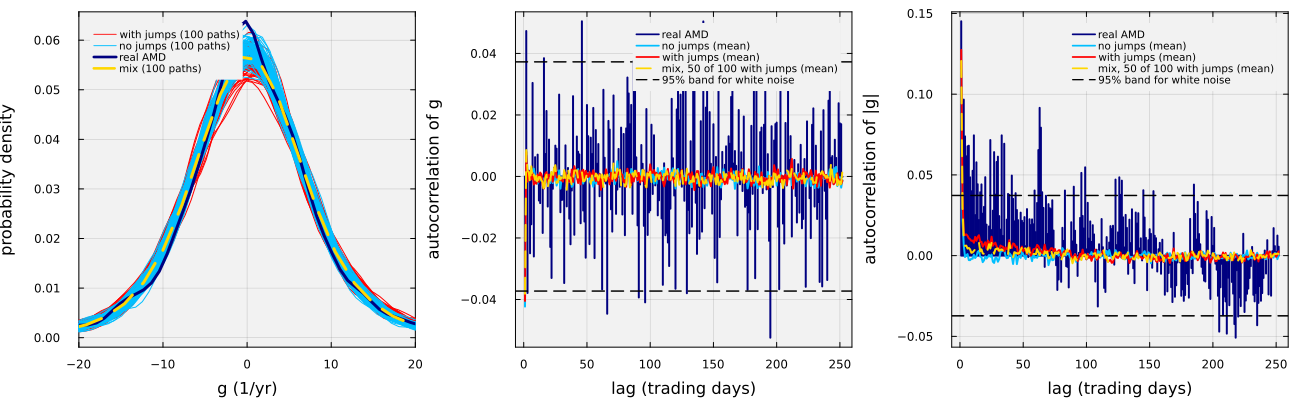

In [13]:
let

    # initialize: the lags, the 95% band, and the real autocorrelations of g and |g| -
    lags = 1:number_of_lags; # trading days
    band = 1.96 / sqrt(number_of_days); # 95% band for the autocorrelation of white noise
    acf_g_real = StatsBase.autocor(g_ticker, lags);
    acf_abs_real = StatsBase.autocor(abs.(g_ticker), lags);

    # the mean autocorrelations of g and |g| over the paths of each group: no jumps, with jumps, and the mix -
    groups = [paths_without, paths_with, paths_mix]; # days × paths, one matrix per group
    number_mix_with = round(Int, fraction_with_jumps * number_of_paths_per_group); # paths with jumps in the mix
    m_g = zeros(number_of_lags, 3); # mean autocorrelation of g, lags × groups
    m_abs = zeros(number_of_lags, 3); # mean autocorrelation of |g|, lags × groups
    for k ∈ 1:3
        n = size(groups[k], 2); # number of paths in group k
        for j ∈ 1:n
            m_g[:, k] = m_g[:, k] + StatsBase.autocor(groups[k][:, j], lags) / n;
            m_abs[:, k] = m_abs[:, k] + StatsBase.autocor(abs.(groups[k][:, j]), lags) / n;
        end
    end

    # display options used in this cell -
    # lw: Set the line width in points.
    # c: Choose the series color.
    # label: Set the legend entry; an empty string omits that series from the legend.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legendfontsize: Set the legend font size in points.
    # seriestype: Draw vertical sticks from zero to each autocorrelation.
    # ls: Choose the line style; :dash draws a dashed line.
    # layout: Arrange the three panels in one row.
    # size: Set the complete figure width and height in pixels.
    # left_margin, bottom_margin: Set the margins; Plots.mm expresses the distance in millimeters.

    # panel 1: the density of the growth rate on each synthetic path of the two groups, the real one on top, and the mix -
    p1 = plot(bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7, legend = :topleft)
    for j ∈ 1:number_of_paths_per_group
        label = ""; # an empty label leaves the path out of the legend
        if j == 1
            label = "with jumps ($(number_of_paths_per_group) paths)";
        end
        density!(p1, paths_with[:, j], lw = 1, c = :red, label = label)
    end
    for j ∈ 1:number_of_paths_per_group
        label = "";
        if j == 1
            label = "no jumps ($(number_of_paths_per_group) paths)";
        end
        density!(p1, paths_without[:, j], lw = 1, c = :deepskyblue1, label = label)
    end
    density!(p1, g_ticker, lw = 3, c = :navy, label = "real $(my_ticker)")
    density!(p1, vec(paths_mix), lw = 3, c = :gold, ls = :dash, # vec stacks the columns of paths_mix into one vector: all mix paths together
        label = "mix ($(number_of_paths_per_group) paths)")
    xlims!(p1, -20, 20)
    xlabel!(p1, "g (1/yr)"); ylabel!(p1, "probability density")

    # panel 2: the autocorrelation of g, real as sticks and each group as a mean -
    p2 = plot(lags, acf_g_real, seriestype = :sticks, lw = 2, c = :navy, label = "real $(my_ticker)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7)
    plot!(p2, lags, m_g[:, 1], lw = 2, c = :deepskyblue1, label = "no jumps (mean)")
    plot!(p2, lags, m_g[:, 2], lw = 2, c = :red, label = "with jumps (mean)")
    plot!(p2, lags, m_g[:, 3], lw = 2, c = :gold, ls = :dash, label = "mix, $(number_mix_with) of $(number_of_paths_per_group) with jumps (mean)")
    hline!(p2, [band, -band], lw = 1.5, ls = :dash, c = :black, label = "95% band for white noise")
    xlabel!(p2, "lag (trading days)"); ylabel!(p2, "autocorrelation of g")

    # panel 3: the autocorrelation of |g|, the same way -
    p3 = plot(lags, acf_abs_real, seriestype = :sticks, lw = 2, c = :navy, label = "real $(my_ticker)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7)
    plot!(p3, lags, m_abs[:, 1], lw = 2, c = :deepskyblue1, label = "no jumps (mean)")
    plot!(p3, lags, m_abs[:, 2], lw = 2, c = :red, label = "with jumps (mean)")
    plot!(p3, lags, m_abs[:, 3], lw = 2, c = :gold, ls = :dash, label = "mix, $(number_mix_with) of $(number_of_paths_per_group) with jumps (mean)")
    hline!(p3, [band, -band], lw = 1.5, ls = :dash, c = :black, label = "95% band for white noise")
    xlabel!(p3, "lag (trading days)"); ylabel!(p3, "autocorrelation of |g|")

    # the three panels in one row -
    plot(p1, p2, p3, layout = (1, 3), size = (1300, 400), left_margin = 5Plots.mm, bottom_margin = 6Plots.mm)
end

Next, let's see how far the paths of one group spread around the group mean. We choose the group by setting `paths_to_visualize` to `paths_without`, `paths_with`, or `paths_mix` in the first code block below.

`Unhide` the second code block to see how we plotted the distribution of the growth rate (left) and the autocorrelation of $|g_{t}|$ (right). Each panel shows the real values, the group mean, and the shaded range from the `lower_percentile` to the `upper_percentile` percentile of the paths. Each distribution comes from a histogram with the same bins for every path:

In [14]:
# uncomment to pick a different group to plot, or leave commented to plot the default group, the mix -
paths_to_visualize = paths_mix; # the group we plot: another name for the same matrix, not a copy
# paths_to_visualize = paths_without; # the group we plot: another name for the same matrix, not a copy
# paths_to_visualize = paths_with; # the group we plot: another name for the same matrix, not a copy

2766×100 Matrix{Float64}:
  2.4218      7.0941    -5.80961   …    2.31208   -4.47371     3.18104
  2.88829     2.90522    2.67152       -3.8098     3.79601    -9.20872
  0.646015   13.3188    -4.86776       -5.31719    5.00081     9.33503
  1.61868    -2.87363    3.73796      -21.52      -6.4521    -16.8886
 14.3707     -2.46488    7.96391      -16.5432     2.88859     0.555035
  4.46143     2.94367   -4.05192   …  -15.3367     9.18915     5.10113
 -3.30608     2.43459   -5.75435       -3.46667   -1.79591   -15.601
  8.82377    -5.00816   -3.90471        3.46866    1.75662    -3.33693
 -8.62617    -0.701767   6.10875        2.79001   -2.48968     1.1932
  3.61917   -27.7044    -3.09412        8.14201   -0.357643   -5.68914
  ⋮                                ⋱                         
 11.1102      0.575668   3.98545      -11.3475     3.75632     9.05246
 -2.20701    12.2347     3.97177       34.953     -4.85212     1.85264
  3.16321    11.4474    -5.61073       -6.27545    8.14156     

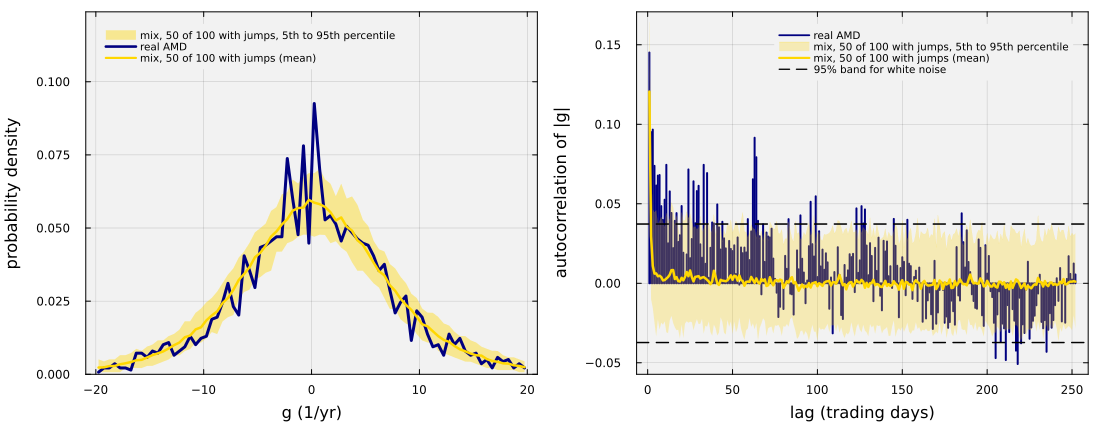

In [15]:
let

    # initialize: the group we plot, and its name and color from the figure above -
    X = paths_to_visualize; # synthetic growth rates of my_ticker in the group we plot, days × paths (1/yr)
    n_paths = size(X, 2); # number of paths in the group
    number_mix_with = round(Int, fraction_with_jumps * number_of_paths_per_group); # paths with jumps in the mix
    name = ""; # stays empty if paths_to_visualize is not one of the three groups
    color = :black;
    if X == paths_without
        name = "no jumps";
        color = :deepskyblue1;
    elseif X == paths_with
        name = "with jumps";
        color = :red;
    elseif X == paths_mix
        name = "mix, $(number_mix_with) of $(number_of_paths_per_group) with jumps";
        color = :gold;
    end

    # the distribution of the growth rate on each path: a histogram with the same bins for every path -
    width = 0.5; # bin width (1/yr)
    edges = -20.0:width:20.0; # bin edges of the growth rate (1/yr), from -20 to 20 in steps of width
    number_of_bins = length(edges) - 1;
    centers = zeros(number_of_bins); # middle of each bin (1/yr)
    for b ∈ 1:number_of_bins
        centers[b] = (edges[b] + edges[b + 1]) / 2;
    end
    D = zeros(number_of_bins, n_paths); # density of the growth rate on each path, bins × paths
    for j ∈ 1:n_paths
        counts = StatsBase.fit(StatsBase.Histogram, X[:, j], edges).weights; # number of days in each bin
        D[:, j] = counts / (number_of_days * width); # fraction of days in each bin, divided by the bin width
    end
    counts_real = StatsBase.fit(StatsBase.Histogram, g_ticker, edges).weights; # the same bins for the real growth rates
    D_real = counts_real / (number_of_days * width); # real density of the growth rate

    # the autocorrelation of |g| on each path -
    lags = 1:number_of_lags; # trading days
    A = zeros(number_of_lags, n_paths); # autocorrelation of |g| on each path, lags × paths
    for j ∈ 1:n_paths
        A[:, j] = StatsBase.autocor(abs.(X[:, j]), lags);
    end
    A_real = StatsBase.autocor(abs.(g_ticker), lags); # real autocorrelation of |g|
    band = 1.96 / sqrt(number_of_days); # 95% band for the autocorrelation of white noise

    # the mean and the lower and upper percentiles over the paths, at each bin and at each lag -
    D_mean = zeros(number_of_bins);
    D_low = zeros(number_of_bins);
    D_high = zeros(number_of_bins);
    for b ∈ 1:number_of_bins
        D_mean[b] = mean(D[b, :]);
        D_low[b] = quantile(D[b, :], lower_percentile / 100);
        D_high[b] = quantile(D[b, :], upper_percentile / 100);
    end
    A_mean = zeros(number_of_lags);
    A_low = zeros(number_of_lags);
    A_high = zeros(number_of_lags);
    for k ∈ 1:number_of_lags
        A_mean[k] = mean(A[k, :]);
        A_low[k] = quantile(A[k, :], lower_percentile / 100);
        A_high[k] = quantile(A[k, :], upper_percentile / 100);
    end

    # display options used in this cell -
    # fillrange: Shade the area between this series and the given lower series.
    # fillalpha: Set the opacity of the shaded area; 0 is clear and 1 is solid.
    # lw = 0: Draw the shaded area without its edge lines.
    # the other options are described in the figure above.
    range_label = "$(name), $(lower_percentile)th to $(upper_percentile)th percentile";

    # left panel: the distribution of the growth rate; the range first, so the lines are drawn on top of it -
    p1 = plot(centers, D_high, fillrange = D_low, fillalpha = 0.4, lw = 0, c = color, label = range_label,
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7, legend = :topleft)
    plot!(p1, centers, D_real, lw = 3, c = :navy, label = "real $(my_ticker)")
    plot!(p1, centers, D_mean, lw = 2.5, c = color, label = "$(name) (mean)")
    y_high = ylims(p1)[2]; # top of the y axis
    ylims!(p1, 0, 1.3 * y_high) # leave room for the legend at the top of the axes
    xlabel!(p1, "g (1/yr)"); ylabel!(p1, "probability density")

    # right panel: the autocorrelation of |g|; the real sticks first, so the more transparent range and the mean of the group are drawn on top of them -
    p2 = plot(lags, A_real, seriestype = :sticks, lw = 2, c = :navy, label = "real $(my_ticker)",
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legendfontsize = 7)
    plot!(p2, lags, A_high, fillrange = A_low, fillalpha = 0.25, lw = 0, c = color, label = range_label)
    plot!(p2, lags, A_mean, lw = 2.5, c = color, label = "$(name) (mean)")
    hline!(p2, [band, -band], lw = 1.5, ls = :dash, c = :black, label = "95% band for white noise")
    xlabel!(p2, "lag (trading days)"); ylabel!(p2, "autocorrelation of |g|")

    # checks: the group is one of the three, and the percentiles are in order -
    @assert name != "" "set paths_to_visualize to paths_without, paths_with, or paths_mix"
    @assert 0 <= lower_percentile < upper_percentile <= 100 "the percentiles must satisfy 0 ≤ lower_percentile < upper_percentile ≤ 100"

    # the two panels in one row -
    plot(p1, p2, layout = (1, 2), size = (1100, 430), left_margin = 5Plots.mm, bottom_margin = 6Plots.mm)
end

> __What do we see?__ In every group, the real density near zero lies above the shaded range. The real stock has more days with small moves than almost every synthetic path.
>
> * __No jumps:__ After a few days, the shaded range of the autocorrelation of $|g_{t}|$ lies close to the 95% band for white noise. The real autocorrelation stays above the shaded range for several months.
> * __With jumps:__ The shaded range is wider, and its upper edge stays above the white-noise band for longer. Most real autocorrelations over the first months are still above the shaded range.
> * __The mix:__ The mean and the shaded range lie between those of the two groups.

Finally, let's save the generator, so the synthetic markets can be drawn again without refitting. We write it to `data/JumpHMM-SectorFactor-Universe-2014-2024.jld2`, with the tickers, the sectors, and the first day's closing prices, which turn synthetic growth rates back into prices:

In [16]:
let

    # save the generator and what it needs to rebuild prices -
    path = joinpath(_PATH_TO_DATA, "JumpHMM-SectorFactor-Universe-2014-2024.jld2");
    save(path, Dict("portfolio" => tuned, "tickers" => tickers, "sectors" => sectors, "first_close" => prices[1, :],
        "N" => number_of_states, "ν" => ν, "Δt" => Δt,
        "ϵ_range" => collect(ϵ_range), "λ_range" => collect(λ_range), "number_of_paths" => number_of_paths, "seed" => random_seed);
        compress = true # compress the file: one fitted model per stock and sector makes it large
    );

    # checks: the file reloads, and the reloaded generator draws the same path -
    # seed = 1 fixes the same random draws for the original and reloaded generators.
    reloaded = load(path, "portfolio");
    G_original = JumpHMM.sample_dependence(tuned.dependence, 10; seed = 1).G; # 10 days from the generator in memory
    G_reloaded = JumpHMM.sample_dependence(reloaded.dependence, 10; seed = 1).G; # 10 days from the reloaded generator
    @assert G_reloaded == G_original "the saved generator should reproduce the same draws"
end

___

## Summary
In this example, we extended the jump hidden Markov model from one asset to a universe of stocks with the sector factor model, compared synthetic paths with the real data, and saved the generator.

> __Key Takeaways:__
>
> * __Baseline and factor contributions:__ We fitted each stock's baseline and market sensitivity with the single index model. We used the residuals to build sector factors and models of what remained after the sector contribution. This separated the shared sources of movement from the stock-specific residuals.
> * __Shared draws reproduce co-movement:__ We combined the saved market model with models of sector factors and stock-specific residuals. Shared market and sector draws made the stocks move together. On our synthetic path, the correlation matrix showed the same sector blocks as the real data.
> * __Jumps add little volatility clustering to one synthetic stock:__ We compared the stylized facts of one stock on paths without jumps, on paths with jumps, and on a mix of the two. In both groups, the synthetic stock had about the same spread as the real one but a far lower excess kurtosis. Jumps added some volatility clustering, which still faded much faster than in the real data.

Knowing how the synthetic universe is built also tells us its limits. For example, stocks in different sectors are linked only through the market draw.

___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success.

Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___